# HaiChau Hotspots — Phân loại “kiểu khu vực” theo cơ cấu ngành hàng

**DAM501 · Đà Nẵng (trung tâm Hải Châu và lân cận)**

Notebook đi theo đúng quy trình của môn:

1. Problem definition → 2. Analytic approach → 3. Data requirements → 4. Data collection → 5. Data understanding →
6. Data preprocessing → 7. Model → 8. Evaluation → 9. Deployment → 10. Feedback

Đầu ra cuối cùng là `data/web/areas.json`, được web `index.html` đọc để hiển thị bản đồ kiểu khu vực.

## 1. Problem definition

**Câu hỏi:** Mỗi khu vực trong trung tâm Đà Nẵng thuộc “kiểu” gì nếu nhìn vào **cơ cấu ngành hàng ăn uống** của nó?

Ví dụ kỳ vọng: *khu cà phê – văn phòng*, *khu ăn sáng dân cư*, *khu ăn đêm / lẩu nướng*, *khu chợ truyền thống*.

**Ai dùng kết quả:** người muốn mở quán (chọn khu phù hợp mô hình), người đi ăn (biết khu nào mạnh món gì), nhóm nghiên cứu đô thị.

**Đầu ra mong muốn**
- Bản đồ chia ô, mỗi ô được gán một kiểu khu vực có tên dễ hiểu.
- Hồ sơ từng kiểu: cơ cấu ngành hàng, mức giá, đánh giá, từ khoá trong bình luận.
- Web tương tác để xem, khoanh vùng và tra cứu.

## 2. Analytic approach

Đây là bài toán **học không giám sát** (không có nhãn “kiểu khu vực” sẵn) → **phân cụm**.

| Thành phần | Lựa chọn | Lý do |
|---|---|---|
| Đơn vị không gian | **Lưới ô 250 m** | Cột phường trong dữ liệu ghi tiếng Anh và có chỗ sai (xem bước 5); lưới đều nhau, so sánh công bằng |
| Đặc trưng | Vector **tỷ lệ** các nhóm ngành hàng trong ô | Đúng định nghĩa “cơ cấu ngành hàng”, không phụ thuộc ô đông hay vắng |
| Giảm nhiễu | Gộp nhóm món, làm mượt không gian, biến đổi Hellinger, PCA | Mỗi ô chỉ có 5–40 quán nên tỷ lệ rất nhiễu |
| Mô hình | **K-Means**, **Hierarchical (Ward)**, **GMM** | So sánh 3 cách tiếp cận: tâm cụm, phân cấp, xác suất |
| Đánh giá | Silhouette, Davies–Bouldin, Calinski–Harabasz, độ ổn định (bootstrap ARI), mức đồng thuận giữa các mô hình, khả năng diễn giải | Không có nhãn thật nên cần nhiều góc nhìn |

Giá và bình luận **không đưa vào phân cụm** (đề tài phân loại theo cơ cấu ngành hàng); chúng dùng để **mô tả** từng kiểu sau khi phân cụm.

## 3. Data requirements

| Dữ liệu cần | Dùng để | Nguồn | Trạng thái |
|---|---|---|---|
| Toạ độ cửa hàng (`latitude`, `longitude`) | Gán quán vào ô lưới | `DaNangData_full.xlsm` | Có |
| Loại hình (`category`, `productType`) | Tính cơ cấu ngành hàng | `DaNangData_full.xlsm` | Có, cần chuẩn hoá (339 giá trị) |
| Tên, địa chỉ, `storeId` | Hiển thị, khử trùng lặp, nối bảng | `DaNangData_full.xlsm` | Có |
| Giá (`price_min`, `price_max`) | Mô tả mức giá từng kiểu | `data/crawl/prices.csv` | **Chưa crawl → dùng giả lập `data/sim/`** |
| Bình luận (`rating`, `comment`) | Đánh giá và từ khoá từng kiểu | `data/crawl/reviews.csv` | **Chưa crawl → dùng giả lập `data/sim/`** |

Định dạng cột của file giá và bình luận được mô tả trong `data/README.md`. Khi có dữ liệu crawl, chỉ cần đặt vào `data/crawl/` rồi chạy lại notebook.

In [1]:
import json, re, subprocess, sys, warnings
from collections import Counter
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score,
                             davies_bouldin_score, silhouette_score)
from sklearn.mixture import GaussianMixture

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 80)
sns.set_theme(style="whitegrid", font_scale=.9)
plt.rcParams["figure.dpi"] = 110

ROOT = Path.cwd()
DATA = ROOT / "data"
(DATA / "processed").mkdir(parents=True, exist_ok=True)
(DATA / "web").mkdir(parents=True, exist_ok=True)
SEED = 501

## 4. Data collection

- Dữ liệu cửa hàng: `data/DaNangData_full.xlsm`.
- Giá và bình luận: ưu tiên `data/crawl/`, nếu chưa có thì dùng `data/sim/`. Nếu cả hai đều chưa có, notebook tự chạy `scripts/simulate_price_comment.py` để sinh dữ liệu giả lập (định dạng giống hệt dữ liệu crawl).

In [2]:
def pick(name):
    for sub in ("crawl", "sim"):
        p = DATA / sub / name
        if p.exists():
            return p, sub
    return None, None

if pick("prices.csv")[0] is None or pick("reviews.csv")[0] is None:
    subprocess.run([sys.executable, str(ROOT / "scripts" / "simulate_price_comment.py")], check=True)

PRICE_PATH, PRICE_SRC = pick("prices.csv")
REVIEW_PATH, REVIEW_SRC = pick("reviews.csv")

stores_raw = pd.read_excel(DATA / "DaNangData_full.xlsm", sheet_name=0, engine="openpyxl")
prices_raw = pd.read_csv(PRICE_PATH)
reviews_raw = pd.read_csv(REVIEW_PATH)

print(f"Cửa hàng : {stores_raw.shape}  ← DaNangData_full.xlsm")
print(f"Giá      : {prices_raw.shape}  ← {PRICE_PATH.relative_to(ROOT)}  ({PRICE_SRC})")
print(f"Bình luận: {reviews_raw.shape}  ← {REVIEW_PATH.relative_to(ROOT)}  ({REVIEW_SRC})")
stores_raw.head(3)

Cửa hàng : (3256, 11)  ← DaNangData_full.xlsm
Giá      : (3256, 4)  ← data\sim\prices.csv  (sim)
Bình luận: (18643, 6)  ← data\sim\reviews.csv  (sim)


,storeName,ward,city,district,address,latitude,longitude,flag,category,productType,storeId
0,Bánh Rán Doraemon,Da Nang - Hai Chau I Ward of Hai Chau District,Da Nang,Q.Hải Châu,"76/17 Trần Phú, Phường Hải Châu 1, Quận Hải Châu",16.069922,108.223651,38,SHOP,Bakery & Baking Supplies,SHOP99231749
1,Chợ Cồn,Da Nang - Tan Chinh Ward of Thanh Khe District,Da Nang,Q.Hải Châu,"Lô 304 Vỉa Hè Đình 6 Chợ Cồn, Phường Hải Châu 2, Quận Hải Châu",16.068166,108.214100,38,SHOP,Bakery & Baking Supplies,SHOP64944787
2,Chợ Cồn,Da Nang - Tan Chinh Ward of Thanh Khe District,Da Nang,Q.Hải Châu,"Lô 129-130 Đình 7 Chợ Cồn, Phường Hải Châu 2, Quận Hải Châu",16.068196,108.214761,38,SHOP,Bakery & Baking Supplies,SHOP51233043


## 5. Data understanding

Kiểm tra chất lượng và phân bố trước khi xử lý: giá trị thiếu, loại hình, toạ độ, phường, giá và đánh giá.

In [3]:
info = pd.DataFrame({
    "kiểu": stores_raw.dtypes.astype(str),
    "thiếu": stores_raw.isna().sum(),
    "số giá trị khác nhau": stores_raw.nunique(),
})
info

,kiểu,thiếu,số giá trị khác nhau
storeName,str,0,2796
ward,str,3,30
city,str,0,1
district,str,0,20
address,str,0,3112
latitude,float64,0,3084
longitude,float64,0,2972
flag,int64,0,12
category,str,0,2
productType,str,0,339


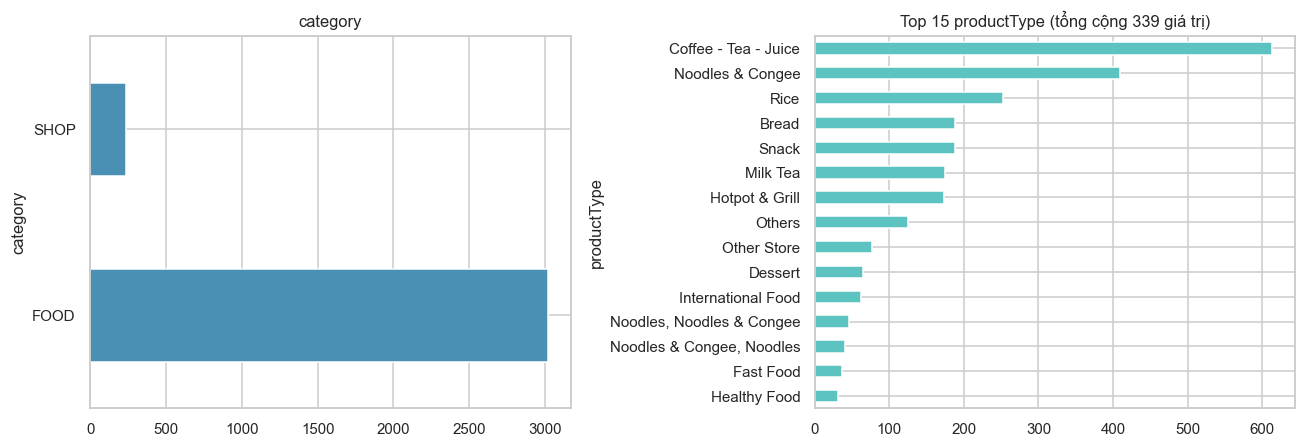

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
stores_raw["category"].value_counts().plot.barh(ax=ax[0], color="#4A90B5")
ax[0].set_title("category")
stores_raw["productType"].value_counts().head(15)[::-1].plot.barh(ax=ax[1], color="#5CC3C1")
ax[1].set_title("Top 15 productType (tổng cộng %d giá trị)" % stores_raw["productType"].nunique())
plt.tight_layout(); plt.show()

**Nhận xét:** `productType` có hơn 300 giá trị vì một quán có thể mang nhiều nhãn (“Rice, Others”, “Noodles & Congee, Rice”…). Cần chuẩn hoá về một số nhóm ngành hàng.

In [5]:
print("Khoảng toạ độ:")
print(stores_raw[["latitude", "longitude"]].describe().loc[["min", "max"]])
far = stores_raw[~stores_raw.latitude.between(15.95, 16.15) | ~stores_raw.longitude.between(108.10, 108.32)]
print(f"\nCửa hàng nằm ngoài Đà Nẵng: {len(far)}")
far[["storeName", "address", "latitude", "longitude"]]

Khoảng toạ độ:
      latitude   longitude
min  10.603378  106.720252
max  20.957988  108.245504

Cửa hàng nằm ngoài Đà Nẵng: 3


,storeName,address,latitude,longitude
2528,Nông Sản Đắk Lắk,"Số 95 Lũng Bắc, Phường Đằng Hải",20.843700,106.720252
2529,Chợ Hàn,"Ki ốt 12 tầng 1 Chợ Hàn, Phường Hải Châu 1",20.957988,107.084943
3174,Camry Quán,"181 Tố Hữu, Phường Hòa Cường Nam, Quận Hải Châu",10.603378,108.213761


In [6]:
print("Cột ward (10 giá trị đầu):")
print(stores_raw["ward"].value_counts().head(10))
print("\nVí dụ phường bị gán sai:")
stores_raw[stores_raw.storeName.str.contains("Chợ Cồn", na=False)][["storeName", "ward", "address"]].head(3)

Cột ward (10 giá trị đầu):
ward
Da Nang - Hai Chau II Ward of Hai Chau District       446
Da Nang - Thach Thang Ward of Hai Chau District       443
Da Nang - Hoa Cuong Bac Ward of Hai Chau District     435
Da Nang - Hoa Thuan Tay Ward of Hai Chau District     354
Da Nang - Nam Duong Ward of Hai Chau District         343
Da Nang - Hai Chau I Ward of Hai Chau District        270
Da Nang - Hoa Cuong Nam Ward of Hai Chau District     215
Da Nang - Binh Thuan Ward of Hai Chau District        200
Da Nang - Tam Thuan Ward of Thanh Khe District        114
Da Nang - Hoa Thuan Dong Ward of Hai Chau District     88
Name: count, dtype: int64

Ví dụ phường bị gán sai:


,storeName,ward,address
1,Chợ Cồn,Da Nang - Tan Chinh Ward of Thanh Khe District,"Lô 304 Vỉa Hè Đình 6 Chợ Cồn, Phường Hải Châu 2, Quận Hải Châu"
2,Chợ Cồn,Da Nang - Tan Chinh Ward of Thanh Khe District,"Lô 129-130 Đình 7 Chợ Cồn, Phường Hải Châu 2, Quận Hải Châu"
21,Chợ Cồn,Da Nang - Tan Chinh Ward of Thanh Khe District,"Lô 52 Đình 9 Chợ Cồn, Phường Hải Châu 2, Quận Hải Châu"


**Nhận xét:** Có cửa hàng toạ độ ở TP.HCM, Hà Nội cần loại. Cột `ward` ghi tiếng Anh và có chỗ sai (Chợ Cồn ở Hải Châu bị gán phường Tân Chính – Thanh Khê) → dùng **lưới ô** làm đơn vị thay cho phường.

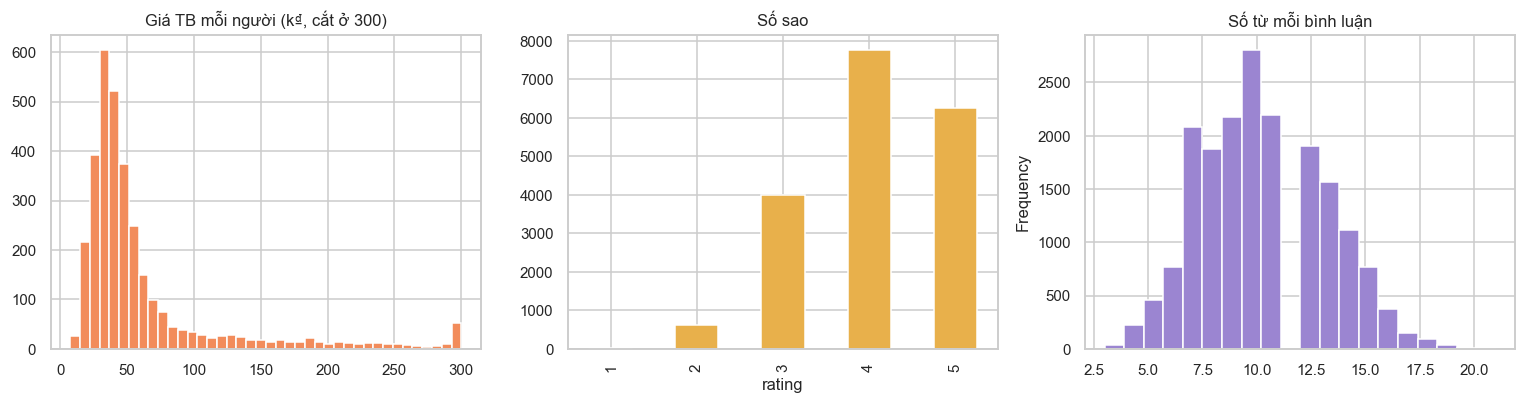

Nguồn giá: sim · nguồn bình luận: sim


,storeId,rating,comment
16160,FOOD22990493,4,"Không gian thoáng, cơm văn phòng ổn áp."
14127,SHOP26006403,5,"Bánh kẹo ở đây ngon nhất khu này, gần chợ."
17590,FOOD67980096,4,"Quán sạch sẽ, xiên que chuẩn vị, giá hợp lý, đi chợ ghé ăn."
5044,FOOD53446981,4,"Quán sạch sẽ, nước ép chuẩn vị, giá rẻ."
17796,FOOD81247286,3,"Ốc ăn được, không quá đặc biệt."


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
p_mid = (prices_raw.price_min + prices_raw.price_max) / 2000
ax[0].hist(p_mid.clip(upper=300), bins=40, color="#F28C5B"); ax[0].set_title("Giá TB mỗi người (k₫, cắt ở 300)")
reviews_raw["rating"].value_counts().sort_index().plot.bar(ax=ax[1], color="#E8B04B"); ax[1].set_title("Số sao")
reviews_raw["comment"].str.split().str.len().plot.hist(ax=ax[2], bins=20, color="#9B85D1"); ax[2].set_title("Số từ mỗi bình luận")
plt.tight_layout(); plt.show()
print(f"Nguồn giá: {PRICE_SRC} · nguồn bình luận: {REVIEW_SRC}")
reviews_raw.sample(5, random_state=SEED)[["storeId", "rating", "comment"]]

## 6. Data preprocessing

1. Loại toạ độ ngoài Đà Nẵng và cửa hàng trùng (cùng tên + cùng toạ độ).
2. Chuẩn hoá `productType` → **nhóm món** (11 nhóm) → **nhóm ngành hàng lớn** (7 nhóm dùng để phân cụm).
3. Nối giá và bình luận theo `storeId`.
4. Chia lưới ô 250 m, giữ các ô có ít nhất 5 quán.
5. Tính vector cơ cấu ngành hàng có **làm mượt không gian**, biến đổi **Hellinger** (căn bậc hai tỷ lệ) và **PCA**.

In [8]:
df = stores_raw[stores_raw.latitude.between(15.95, 16.15) & stores_raw.longitude.between(108.10, 108.32)]
n0 = len(df)
df = df.drop_duplicates(["storeName", "latitude", "longitude"]).copy()
print(f"{len(stores_raw)} → {n0} (bỏ toạ độ sai) → {len(df)} (bỏ trùng)")

3256 → 3253 (bỏ toạ độ sai) → 3219 (bỏ trùng)


In [9]:
# Nhóm món: so khớp từ khoá với nhãn đầu tiên của productType, nếu nhãn đầu là "Others" thì xét các nhãn sau
GROUP_RULES = [
    ("lau_nuong", ["Hotpot & Grill", "Beef", "BBQ"]),
    ("tra_sua",   ["Milk Tea"]),
    ("ca_phe",    ["Coffee - Tea - Juice"]),
    ("bun_pho",   ["Noodles", "Congee"]),
    ("com",       ["Rice", "Chicken"]),
    ("banh_mi",   ["Bread", "Bánh Truyền Thống"]),
    ("an_vat",    ["Snack", "Dessert", "Chè"]),
    ("quoc_te",   ["International Food", "Pizza", "Korean", "Japanese", "Dimsum", "Fast Food"]),
    ("healthy",   ["Healthy Food", "Vegetarian"]),
]
SUB_LABEL = {"ca_phe": "Cà phê", "tra_sua": "Trà sữa", "bun_pho": "Bún · phở · mì", "com": "Cơm", "banh_mi": "Bánh mì · bánh",
             "an_vat": "Ăn vặt · chè", "lau_nuong": "Lẩu · nướng", "quoc_te": "Món quốc tế", "healthy": "Healthy",
             "cua_hang": "Cửa hàng · chợ", "khac": "Khác"}
# Nhóm ngành hàng lớn dùng để phân cụm (gộp các nhóm món gần nhau để giảm nhiễu)
MACRO = {"ca_phe": "do_uong", "tra_sua": "do_uong", "bun_pho": "an_sang", "banh_mi": "an_sang", "com": "com",
         "an_vat": "an_vat", "lau_nuong": "lau_nuong", "quoc_te": "quoc_te", "healthy": "quoc_te", "cua_hang": "cho_cua_hang"}
GROUPS = {"do_uong": ("Đồ uống", "Cà phê, trà sữa"), "an_sang": ("Bún phở · bánh mì", "Món nước, bánh mì, bánh"),
          "com": ("Cơm", "Cơm, cơm gà, cơm văn phòng"), "an_vat": ("Ăn vặt · chè", "Ăn vặt, chè, tráng miệng"),
          "lau_nuong": ("Lẩu · nướng", "Lẩu, nướng, quán nhậu"), "quoc_te": ("Quốc tế · healthy", "Pizza, gà rán, Hàn, Nhật, healthy"),
          "cho_cua_hang": ("Chợ · cửa hàng", "Đồ khô, đặc sản, tạp hoá")}
G = list(GROUPS)

def food_group(category, product_type):
    if category == "SHOP":
        return "cua_hang"
    first = str(product_type).split(",")[0].strip()
    for g, keys in GROUP_RULES:
        if any(k in first for k in keys):
            return g
    for g, keys in GROUP_RULES:
        if any(k in str(product_type) for k in keys):
            return g
    return "khac"

df["sub"] = [food_group(c, p) for c, p in zip(df.category, df.productType)]
df["g"] = df["sub"].map(MACRO)
summary = df.groupby(["g", "sub"], dropna=False).size().rename("số quán").reset_index()
print(f"Bỏ {df.g.isna().sum()} quán nhóm 'Khác' (không xác định được ngành hàng)")
df = df[df.g.notna()].copy()
summary

Bỏ 43 quán nhóm 'Khác' (không xác định được ngành hàng)


,g,sub,số quán
0,an_sang,banh_mi,237
1,an_sang,bun_pho,596
2,an_vat,an_vat,376
3,cho_cua_hang,cua_hang,230
4,com,com,345
5,do_uong,ca_phe,684
6,do_uong,tra_sua,220
7,lau_nuong,lau_nuong,239
8,quoc_te,healthy,48
9,quoc_te,quoc_te,201


In [10]:
# Giá: trung bình khoảng giá; bình luận: điểm TB, số bình luận, gom nội dung
prices = prices_raw.assign(price_avg=(prices_raw.price_min + prices_raw.price_max) / 2)[["storeId", "price_min", "price_max", "price_avg"]]
rev = reviews_raw.sort_values("created_at", ascending=False)
rev_agg = rev.groupby("storeId").agg(rating=("rating", "mean"), n_reviews=("rating", "size"))
df = df.merge(prices, on="storeId", how="left").merge(rev_agg, on="storeId", how="left")
df["n_reviews"] = df["n_reviews"].fillna(0).astype(int)
print(f"Có giá: {df.price_avg.notna().mean():.0%} · có bình luận: {(df.n_reviews > 0).mean():.0%}")
df[["storeName", "sub", "g", "price_min", "price_max", "rating", "n_reviews"]].head()

Có giá: 100% · có bình luận: 91%


,storeName,sub,g,price_min,price_max,rating,n_reviews
0,Bánh Rán Doraemon,cua_hang,cho_cua_hang,26000,60000,3.333333,3
1,Chợ Cồn,cua_hang,cho_cua_hang,59000,99000,4.235294,17
2,Chợ Cồn,cua_hang,cho_cua_hang,22000,40000,3.833333,6
3,Tiệm Bánh Bảo Tiên,cua_hang,cho_cua_hang,13000,21000,3.500000,4
4,Chè Singapore,an_vat,an_vat,25000,49000,4.500000,2


230 ô có quán → giữ 138 ô (≥ 5 quán), chứa 3010/3176 quán


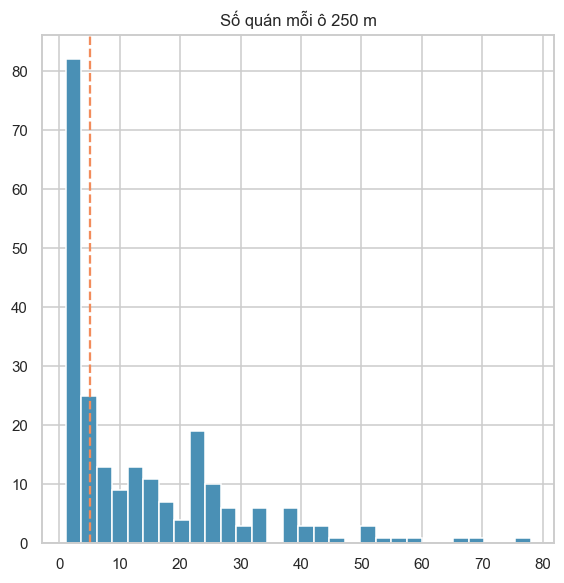

In [11]:
# Lưới ô 250 m: chiếu toạ độ ra mét quanh vĩ độ trung bình (sai số không đáng kể ở phạm vi vài km)
CELL = 250        # cạnh ô (m)
MIN_STORES = 5    # ô có ít hơn số quán này bị bỏ vì tỷ lệ quá nhiễu
BW = 250          # bán kính làm mượt (m)
LNG0, LAT0 = 108.15, 15.95
KX, KY = 111_320 * np.cos(np.radians(df.latitude.mean())), 110_574

df["x"], df["y"] = (df.longitude - LNG0) * KX, (df.latitude - LAT0) * KY
df["cx"], df["cy"] = (df.x // CELL).astype(int), (df.y // CELL).astype(int)
df["cell"] = df.cx.astype(str) + "_" + df.cy.astype(str)

cnt = df.groupby("cell").size()
cells = pd.DataFrame({"cell": cnt[cnt >= MIN_STORES].index})
cells[["cx", "cy"]] = cells.cell.str.split("_", expand=True).astype(int)
print(f"{df.cell.nunique()} ô có quán → giữ {len(cells)} ô (≥ {MIN_STORES} quán), "
      f"chứa {int(cnt[cnt >= MIN_STORES].sum())}/{len(df)} quán")

fig, ax = plt.subplots(figsize=(6, 6))
ax.hist(cnt, bins=30, color="#4A90B5"); ax.axvline(MIN_STORES, color="#F28C5B", ls="--")
ax.set_title("Số quán mỗi ô 250 m"); plt.show()

In [12]:
# Cơ cấu thô (đếm trong ô) và cơ cấu làm mượt: mỗi quán đóng góp cho tâm ô với trọng số Gauss theo khoảng cách
raw = pd.crosstab(df.cell, df.g).reindex(index=cells.cell, columns=G, fill_value=0)
centers = np.c_[(cells.cx + .5) * CELL, (cells.cy + .5) * CELL]
onehot = pd.get_dummies(df.g).reindex(columns=G, fill_value=0).values.astype(float)
dist2 = ((centers[:, None, :] - df[["x", "y"]].values[None, :, :]) ** 2).sum(-1)
W = np.exp(-dist2 / (2 * BW ** 2))
comp = W @ onehot
comp = comp / comp.sum(1, keepdims=True)

X_hel = np.sqrt(comp)                      # Hellinger: phù hợp hơn cho dữ liệu tỷ lệ khi dùng khoảng cách Euclid
pca = PCA(n_components=3, random_state=SEED).fit(X_hel)
Z = pca.transform(X_hel)
print("Tỷ lệ phương sai giải thích bởi 3 thành phần PCA:", np.round(pca.explained_variance_ratio_, 3),
      "→ tổng", round(pca.explained_variance_ratio_.sum(), 3))

features = pd.DataFrame(comp, columns=[f"p_{g}" for g in G]).assign(cell=cells.cell.values, n_stores=raw.sum(1).values)
features.to_csv(DATA / "processed" / "cells_features.csv", index=False)
df.to_csv(DATA / "processed" / "stores_clean.csv", index=False)
features.head()

Tỷ lệ phương sai giải thích bởi 3 thành phần PCA: [0.352 0.259 0.126] → tổng 0.737


,p_do_uong,p_an_sang,p_com,p_an_vat,p_lau_nuong,p_quoc_te,p_cho_cua_hang,cell,n_stores
0,0.375522,0.325919,0.150255,0.038139,0.023549,0.014512,0.072104,23_46,6
1,0.324599,0.323800,0.105463,0.051122,0.061737,0.020317,0.112961,25_40,6
2,0.303680,0.340555,0.136623,0.036981,0.055478,0.015480,0.111203,25_41,13
3,0.282677,0.329098,0.160975,0.051691,0.067555,0.018120,0.089884,25_42,27
4,0.305716,0.287778,0.156439,0.082279,0.080902,0.016999,0.069887,25_43,7


**Vì sao cần làm mượt và gộp nhóm?** Ở bản nháp, phân cụm thẳng tỷ lệ thô của 11 nhóm món cho silhouette chỉ khoảng 0.1: mỗi ô quá ít quán so với số nhóm. Gộp còn 7 nhóm và làm mượt bán kính 250 m (mỗi ô “mượn” thông tin từ quán lân cận) giúp cấu trúc rõ hơn. Bán kính được giữ vừa phải vì làm mượt quá tay sẽ khiến các ô kề nhau giống nhau một cách nhân tạo và làm điểm số đẹp giả.

## 7. Model

Chạy 3 mô hình với số cụm k = 3…7 trên không gian PCA:

- **K-Means**: chia theo tâm cụm, nhanh, dễ diễn giải.
- **Hierarchical (Ward)**: gộp dần các ô giống nhau, xem được cây phân cấp.
- **GMM**: mỗi cụm là một phân phối Gauss, cho xác suất thuộc cụm.

Độ ổn định của K-Means được đo bằng bootstrap: lấy mẫu lại các ô 30 lần, huấn luyện lại, rồi so nhãn với mô hình gốc (ARI).

In [13]:
def stability(Z, k, n_boot=30):
    base = KMeans(k, n_init=20, random_state=SEED).fit_predict(Z)
    rng = np.random.default_rng(SEED)
    scores = []
    for b in range(n_boot):
        idx = rng.choice(len(Z), len(Z), replace=True)
        m = KMeans(k, n_init=10, random_state=b).fit(Z[idx])
        scores.append(adjusted_rand_score(base, m.predict(Z)))
    return float(np.mean(scores))

MODELS = {
    "K-Means": lambda k: KMeans(k, n_init=50, random_state=SEED).fit_predict(Z),
    "Hierarchical": lambda k: AgglomerativeClustering(k, linkage="ward").fit_predict(Z),
    "GMM": lambda k: GaussianMixture(k, covariance_type="full", n_init=10, random_state=SEED).fit(Z).predict(Z),
}
rows, labels = [], {}
for k in range(3, 8):
    for name, fit in MODELS.items():
        lab = fit(k); labels[(name, k)] = lab
        rows.append({"model": name, "k": k, "silhouette": silhouette_score(Z, lab),
                     "davies_bouldin": davies_bouldin_score(Z, lab), "calinski_harabasz": calinski_harabasz_score(Z, lab),
                     "stability": stability(Z, k) if name == "K-Means" else np.nan})
scores = pd.DataFrame(rows)
scores.pivot(index="k", columns="model", values="silhouette").round(3)

model,GMM,Hierarchical,K-Means
k,,,
3,0.337,0.316,0.348
4,0.265,0.319,0.296
5,0.139,0.294,0.295
6,0.265,0.311,0.303
7,0.164,0.289,0.294


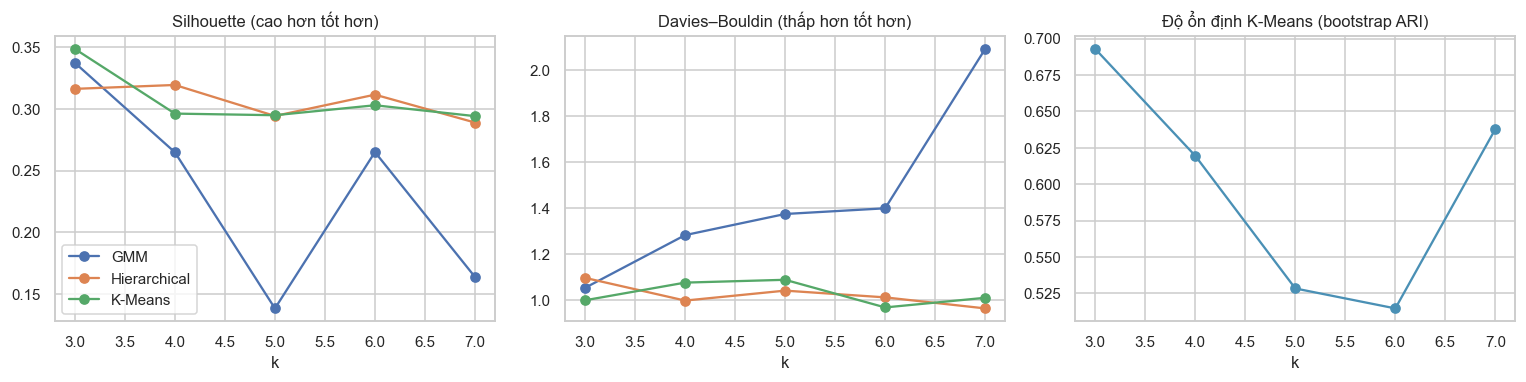

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for name, g in scores.groupby("model"):
    ax[0].plot(g.k, g.silhouette, marker="o", label=name)
    ax[1].plot(g.k, g.davies_bouldin, marker="o", label=name)
km = scores[scores.model == "K-Means"]
ax[2].plot(km.k, km.stability, marker="o", color="#4A90B5")
ax[0].set_title("Silhouette (cao hơn tốt hơn)"); ax[1].set_title("Davies–Bouldin (thấp hơn tốt hơn)")
ax[2].set_title("Độ ổn định K-Means (bootstrap ARI)"); ax[0].legend()
for a in ax: a.set_xlabel("k")
plt.tight_layout(); plt.show()

In [15]:
# Chọn mô hình và k:
# - K-Means: ổn định và dễ giải thích nhất trong 3 mô hình (GMM dao động mạnh theo k).
# - Mục tiêu ở bước 1 cần ít nhất 4 kiểu khu vực, nên xét k = 4…7 (k = 3 quá thô dù silhouette cao nhất).
# - Chỉ giữ k có độ ổn định ≥ 0.5, rồi chọn k có tổng thứ hạng tốt nhất theo silhouette, Davies–Bouldin
#   và độ ổn định; hoà thì chọn silhouette cao hơn.
METHOD = "K-Means"
cand = scores[(scores.model == METHOD) & scores.k.between(4, 7) & (scores.stability >= .5)].copy()
cand["rank_sum"] = (cand.silhouette.rank(ascending=False) + cand.davies_bouldin.rank()
                    + cand.stability.rank(ascending=False))
K = int(cand.sort_values(["rank_sum", "silhouette"], ascending=[True, False]).k.iloc[0])
display(cand.round(3))
label = labels[(METHOD, K)]
print(f"Chọn {METHOD} với k = {K}")
scores[scores.k == K].round(3)

,model,k,silhouette,davies_bouldin,calinski_harabasz,stability,rank_sum
3,K-Means,4,0.296,1.075,71.318,0.619,7.0
6,K-Means,5,0.295,1.088,67.323,0.528,10.0
9,K-Means,6,0.303,0.967,65.943,0.515,6.0
12,K-Means,7,0.294,1.009,66.370,0.638,7.0


Chọn K-Means với k = 6


,model,k,silhouette,davies_bouldin,calinski_harabasz,stability
9,K-Means,6,0.303,0.967,65.943,0.515
10,Hierarchical,6,0.311,1.011,57.333,NaN
11,GMM,6,0.265,1.399,44.639,NaN


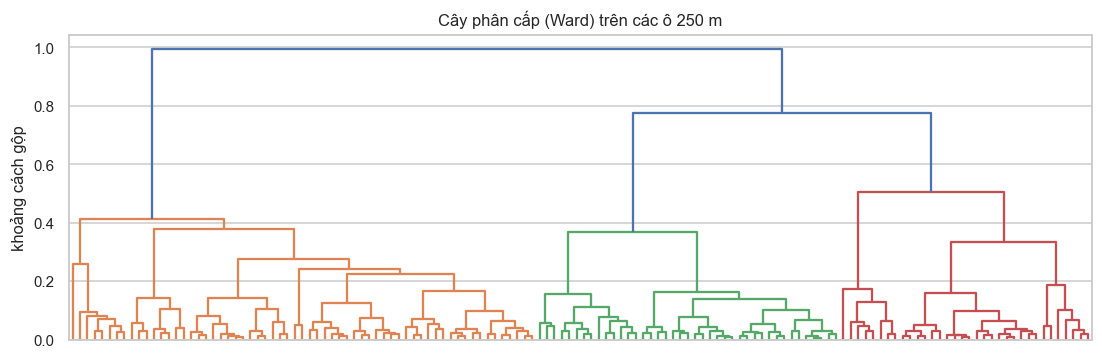

In [16]:
plt.figure(figsize=(12, 3.6))
dendrogram(linkage(Z, method="ward"), no_labels=True, color_threshold=None)
plt.title("Cây phân cấp (Ward) trên các ô 250 m"); plt.ylabel("khoảng cách gộp"); plt.show()

## 8. Evaluation

Đánh giá mô hình đã chọn theo 4 góc:

1. **Chỉ số nội tại** ở k đã chọn (bảng phía trên).
2. **Đồng thuận giữa các mô hình**: K-Means, Hierarchical và GMM có chia giống nhau không (ARI).
3. **Hình dạng cụm** trên không gian PCA.
4. **Diễn giải**: mỗi cụm nổi trội nhóm ngành hàng nào so với mức chung (lift), từ đó đặt tên.

In [17]:
agree = pd.DataFrame([[adjusted_rand_score(labels[(a, K)], labels[(b, K)]) for b in MODELS] for a in MODELS],
                     index=list(MODELS), columns=list(MODELS)).round(2)
print(f"ARI giữa các mô hình ở k = {K} (1 = chia giống hệt, 0 = ngẫu nhiên)")
agree

ARI giữa các mô hình ở k = 6 (1 = chia giống hệt, 0 = ngẫu nhiên)


,K-Means,Hierarchical,GMM
K-Means,1.00,0.52,0.55
Hierarchical,0.52,1.00,0.63
GMM,0.55,0.63,1.00


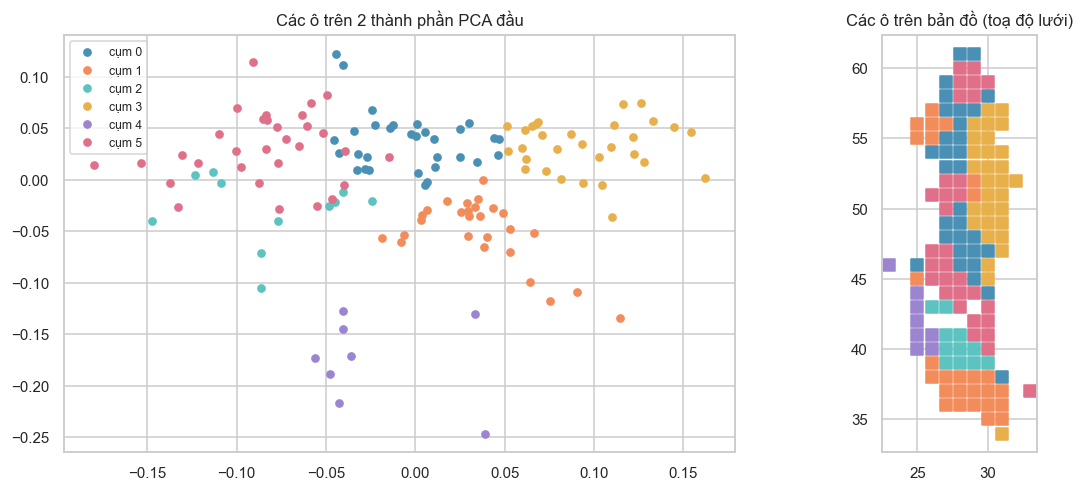

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
pal = ["#4A90B5", "#F28C5B", "#5CC3C1", "#E8B04B", "#9B85D1", "#E0708A", "#7DB46C", "#6C8FD8"]
for c in range(K):
    m = label == c
    ax[0].scatter(Z[m, 0], Z[m, 1], s=22, color=pal[c], label=f"cụm {c}")
    ax[1].scatter(cells.cx[m], cells.cy[m], s=60, marker="s", color=pal[c])
ax[0].set_title("Các ô trên 2 thành phần PCA đầu"); ax[0].legend(fontsize=8)
ax[1].set_title("Các ô trên bản đồ (toạ độ lưới)"); ax[1].set_aspect("equal")
plt.tight_layout(); plt.show()

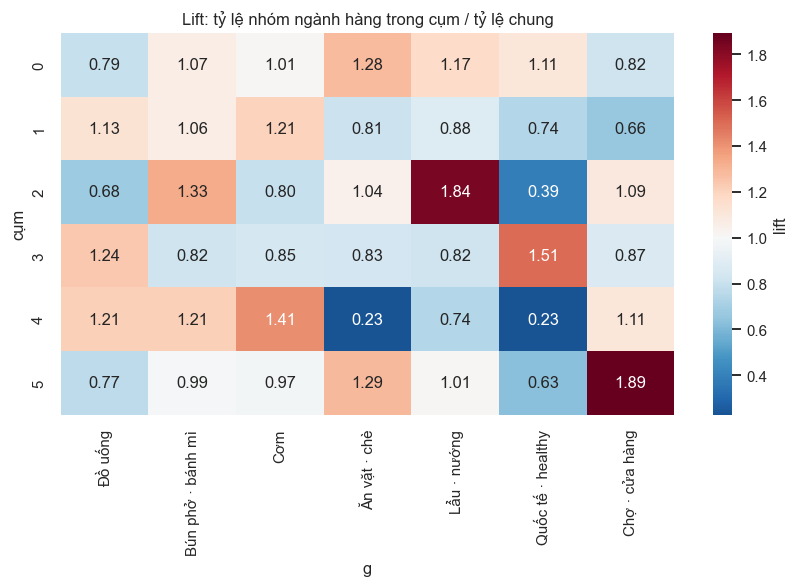

In [19]:
# Hồ sơ cụm dựa trên số đếm THÔ (không làm mượt) để diễn giải trung thực
city_share = raw.sum() / raw.values.sum()
prof = pd.DataFrame({c: raw[label == c].sum() / raw[label == c].values.sum() for c in range(K)}).T
lift = prof / city_share

plt.figure(figsize=(9, .55 * K + 1.2))
sns.heatmap(lift.rename(columns={g: GROUPS[g][0] for g in G}), annot=True, fmt=".2f", cmap="RdBu_r", center=1, cbar_kws={"label": "lift"})
plt.title("Lift: tỷ lệ nhóm ngành hàng trong cụm / tỷ lệ chung"); plt.ylabel("cụm"); plt.show()

In [20]:
# Đặt tên tự động theo nhóm có lift cao nhất (mỗi tên chỉ dùng một lần), để chạy lại với dữ liệu mới vẫn ra tên hợp lý
NAMES = {"cho_cua_hang": "Khu chợ truyền thống", "lau_nuong": "Khu ăn đêm – lẩu nướng", "quoc_te": "Khu du lịch – quốc tế",
         "do_uong": "Khu cà phê – văn phòng", "com": "Khu văn phòng – cơm trưa", "an_sang": "Khu dân cư – ăn sáng",
         "an_vat": "Khu ăn vặt – học sinh"}
used, type_name = set(), {}
for c in lift.max(1).sort_values(ascending=False).index:
    for g in lift.loc[c].sort_values(ascending=False).index:
        if NAMES[g] not in used and lift.loc[c, g] >= 1:
            type_name[c] = NAMES[g]; used.add(NAMES[g]); break
    else:
        type_name[c] = "Khu hỗn hợp"

def describe(c):
    top = lift.loc[c].sort_values(ascending=False)
    top = top[top > 1.05].head(2)
    if top.empty:
        return "Cơ cấu gần với mức chung của thành phố"
    return "Nhiều " + " và ".join(f"{GROUPS[g][0].lower()} (×{v:.1f})" for g, v in top.items()) + " hơn mức chung"

types = pd.DataFrame({"cụm": range(K), "tên": [type_name[c] for c in range(K)], "mô tả": [describe(c) for c in range(K)],
                      "số ô": [int((label == c).sum()) for c in range(K)],
                      "số quán": [int(raw[label == c].values.sum()) for c in range(K)]})
types

,cụm,tên,mô tả,số ô,số quán
0,0,Khu ăn vặt – học sinh,Nhiều ăn vặt · chè (×1.3) và lẩu · nướng (×1.2) hơn mức chung,31,728
1,1,Khu cà phê – văn phòng,Nhiều cơm (×1.2) và đồ uống (×1.1) hơn mức chung,27,624
2,2,Khu ăn đêm – lẩu nướng,Nhiều lẩu · nướng (×1.8) và bún phở · bánh mì (×1.3) hơn mức chung,11,164
3,3,Khu du lịch – quốc tế,Nhiều quốc tế · healthy (×1.5) và đồ uống (×1.2) hơn mức chung,30,893
4,4,Khu văn phòng – cơm trưa,Nhiều cơm (×1.4) và đồ uống (×1.2) hơn mức chung,8,112
5,5,Khu chợ truyền thống,Nhiều chợ · cửa hàng (×1.9) và ăn vặt · chè (×1.3) hơn mức chung,31,489


In [21]:
# Mô tả thêm bằng giá và bình luận (không dùng để phân cụm)
cell_type = dict(zip(cells.cell, label))
df["type"] = df.cell.map(cell_type)

def phrases(texts):
    # Tách bình luận thành các cụm ngắn theo dấu câu, giữ các cụm 2–4 từ
    c = Counter()
    for t in texts:
        for part in re.split(r"[,.!?;]", str(t).lower()):
            w = part.strip().split()
            if 2 <= len(w) <= 4:
                c[" ".join(w)] += 1
    return c

ALL_PHRASES = phrases(reviews_raw.comment)
N_ALL = sum(ALL_PHRASES.values())

def keywords(texts, top=6, min_count=3):
    # Từ khoá ĐẶC TRƯNG: cụm từ xuất hiện trong nhóm nhiều hơn hẳn mức chung (tỷ lệ × log tần suất),
    # để tránh các câu chung chung kiểu "sẽ quay lại" xuất hiện ở mọi nơi
    c = phrases(texts)
    n = sum(c.values()) or 1
    score = {w: (k / n) / (ALL_PHRASES[w] / N_ALL) * np.log1p(k) for w, k in c.items() if k >= min_count}
    return [w for w, _ in sorted(score.items(), key=lambda x: -x[1])[:top]]

rev_with_type = reviews_raw.merge(df[["storeId", "type", "cell"]], on="storeId")
prof_extra = df[df.type.notna()].groupby("type").agg(gia_tb=("price_avg", "median"), danh_gia=("rating", "mean"),
                                                     binh_luan=("n_reviews", "sum"))
prof_extra["từ khoá"] = [", ".join(keywords(rev_with_type[rev_with_type.type == c].comment, 4)) for c in prof_extra.index]
prof_extra.index = [type_name[int(c)] for c in prof_extra.index]
prof_extra["gia_tb"] = (prof_extra.gia_tb / 1000).round(0).astype(int).astype(str) + "k₫"
prof_extra.round(2)

,gia_tb,danh_gia,binh_luan,từ khoá
Khu ăn vặt – học sinh,42k₫,4.05,4063,"quán sạch sẽ, đáng tiền, giá sinh viên, nhân viên thân thiện"
Khu cà phê – văn phòng,41k₫,4.03,3726,"đi chơi buổi tối, sẽ quay lại, nhân viên thân thiện, không gian thoáng"
Khu ăn đêm – lẩu nướng,42k₫,4.05,876,"bò nướng rất ngon, nướng ngói chuẩn vị, bánh xèo bình thường, mở cửa khuya"
Khu du lịch – quốc tế,46k₫,4.08,5100,"view sông đẹp, khách du lịch đông, hẹn bạn buổi chiều, đi cùng gia đình"
Khu văn phòng – cơm trưa,34k₫,4.01,655,"tiện mang đi, nước ép rất ngon, cháo lòng bình thường, trà đào bình thường"
Khu chợ truyền thống,40k₫,4.03,2785,"ăn vặt buổi tối, trái cây ngon, mua làm quà, gần chợ"


**Kết luận đánh giá**
- Silhouette ở mức vừa phải: các kiểu khu vực **chuyển tiếp dần** chứ không tách bạch, điều này hợp lý với đô thị thật.
- Ba mô hình đồng thuận ở mức trung bình (ARI ~0.4–0.5), tức cấu trúc chính không phụ thuộc vào thuật toán.
- Bảng lift cho thấy mỗi cụm có nhóm ngành hàng nổi trội rõ, nên có thể đặt tên ý nghĩa.
- Giá và bình luận hiện là **giả lập**, nên phần mô tả giá/đánh giá chỉ minh hoạ cách dùng. Cơ cấu ngành hàng và phân cụm dùng dữ liệu thật.

## 9. Deployment

Xuất toàn bộ kết quả ra `data/web/areas.json`. Web `index.html` đọc file này để vẽ bản đồ kiểu khu vực.

**Nạp dữ liệu mới:** chạy lại notebook (ví dụ sau khi thêm `data/crawl/`), file JSON được ghi đè, tải lại trang web. Web cũng có nút *Nạp dữ liệu* để mở một file JSON khác.

In [22]:
PALETTE = ["#4A90B5", "#F28C5B", "#5CC3C1", "#E8B04B", "#9B85D1", "#E0708A", "#7DB46C", "#6C8FD8"]
to_ll = lambda x, y: [round(LAT0 + y / KY, 6), round(LNG0 + x / KX, 6)]
row = scores[(scores.model == METHOD) & (scores.k == K)].iloc[0]

cell_rows = []
for i, r in cells.iterrows():
    s = df[df.cell == r.cell]
    rv = rev_with_type[rev_with_type.cell == r.cell]
    cell_rows.append({
        "id": r.cell, "t": int(label[i]),
        "b": [to_ll(r.cx * CELL, r.cy * CELL), to_ll((r.cx + 1) * CELL, (r.cy + 1) * CELL)],
        "n": int(len(s)), "counts": {g: int(raw.loc[r.cell, g]) for g in G if raw.loc[r.cell, g]},
        "price": None if s.price_avg.isna().all() else int(s.price_avg.median()),
        "rating": None if s.rating.isna().all() else round(float(np.average(s.rating.dropna(), weights=s.n_reviews[s.rating.notna()])), 2),
        "reviews": int(s.n_reviews.sum()), "kw": keywords(rv.comment, 5, min_count=2),
    })

type_rows = []
for c in range(K):
    s = df[df.type == c]
    type_rows.append({
        "id": c, "name": type_name[c], "desc": describe(c), "color": PALETTE[c % len(PALETTE)],
        "cells": int((label == c).sum()), "stores": int(len(s)),
        "share": {g: round(float(prof.loc[c, g]), 4) for g in G}, "lift": {g: round(float(lift.loc[c, g]), 2) for g in G},
        "price": None if s.price_avg.isna().all() else int(s.price_avg.median()),
        "rating": None if s.rating.isna().all() else round(float(s.rating.mean()), 2),
        "kw": keywords(rev_with_type[rev_with_type.type == c].comment, 6),
    })

top_comments = rev.groupby("storeId").head(3).groupby("storeId").apply(
    lambda x: [[int(a), b] for a, b in zip(x.rating, x.comment)]).to_dict()
store_rows = [{
    "id": s.storeId, "n": s.storeName, "la": round(s.latitude, 6), "ln": round(s.longitude, 6), "g": s.g, "sub": SUB_LABEL[s["sub"]],
    "pmin": None if pd.isna(s.price_min) else int(s.price_min), "pmax": None if pd.isna(s.price_max) else int(s.price_max),
    "r": None if pd.isna(s.rating) else round(float(s.rating), 1), "rc": int(s.n_reviews),
    "c": s.cell if s.cell in cell_type else None, "cm": top_comments.get(s.storeId, []),
} for _, s in df.iterrows()]

out = {
    "meta": {
        "title": "Kiểu khu vực ẩm thực Đà Nẵng", "generated_at": datetime.now().isoformat(timespec="seconds"),
        "source": {"stores": "DaNangData_full.xlsm", "prices": PRICE_SRC, "reviews": REVIEW_SRC},
        "cell_m": CELL, "min_stores": MIN_STORES, "smooth_m": BW, "method": METHOD, "k": K,
        "metrics": {"silhouette": round(float(row.silhouette), 3), "davies_bouldin": round(float(row.davies_bouldin), 3),
                    "stability": round(float(row.stability), 3),
                    "ari_hc": float(agree.loc[METHOD, "Hierarchical"]), "ari_gmm": float(agree.loc[METHOD, "GMM"])},
        "n_stores": len(df), "n_cells": len(cells),
    },
    "groups": [{"id": g, "label": GROUPS[g][0], "detail": GROUPS[g][1], "city": round(float(city_share[g]), 4)} for g in G],
    "types": type_rows, "cells": cell_rows, "stores": store_rows,
}
path = DATA / "web" / "areas.json"
path.write_text(json.dumps(out, ensure_ascii=False, separators=(",", ":")), encoding="utf-8")
print(f"Đã ghi {path.relative_to(ROOT)} ({path.stat().st_size / 1024:.0f} KB): "
      f"{len(type_rows)} kiểu, {len(cell_rows)} ô, {len(store_rows)} quán")

Đã ghi data\web\areas.json (1074 KB): 6 kiểu, 138 ô, 3176 quán


## 10. Feedback

**Hạn chế hiện tại**
- Giá và bình luận đang **giả lập** → cần crawl thật (định dạng trong `data/README.md`) rồi chạy lại notebook.
- Kết quả nhạy với kích thước ô và bán kính làm mượt; nên thử 200/300 m và báo cáo độ ổn định.
- Dữ liệu cửa hàng có thể thiếu quán nhỏ, quán vỉa hè (thiên về quán có trên nền tảng giao đồ ăn).

**Vòng phản hồi**
1. Người dùng xem web, góp ý tên kiểu khu vực có đúng thực tế không (ví dụ người dân địa phương).
2. Điều chỉnh bảng gộp nhóm món, bảng đặt tên hoặc tham số lưới ở bước 6–8.
3. Bổ sung dữ liệu (crawl giá, bình luận, giờ mở cửa) → chạy lại notebook → web tự cập nhật qua `areas.json`.

**Hướng mở rộng:** thêm đặc trưng giờ mở cửa (tách rõ ăn sáng / ăn đêm), phân tích cảm xúc bình luận, so sánh theo thời gian.

In [23]:
print("Nguồn dữ liệu lần chạy này:", {"giá": PRICE_SRC, "bình luận": REVIEW_SRC})
if "sim" in (PRICE_SRC, REVIEW_SRC):
    print("→ Đang dùng dữ liệu giả lập. Đặt file crawl vào data/crawl/ rồi chạy lại notebook để thay thế.")

Nguồn dữ liệu lần chạy này: {'giá': 'sim', 'bình luận': 'sim'}
→ Đang dùng dữ liệu giả lập. Đặt file crawl vào data/crawl/ rồi chạy lại notebook để thay thế.
